In [83]:
import numpy as np
import os

data = np.load('data/processed/dataset.npz')

images = np.array(data['images'])
labels = np.array(data['labels'])

print(f"Images shape: {images.shape}")
print(f"Labels shape: {labels.shape}")

Images shape: (7023, 224, 224, 3)
Labels shape: (7023,)


/tmp/ipykernel_44/277708508.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=classes, y=counts, palette="viridis")


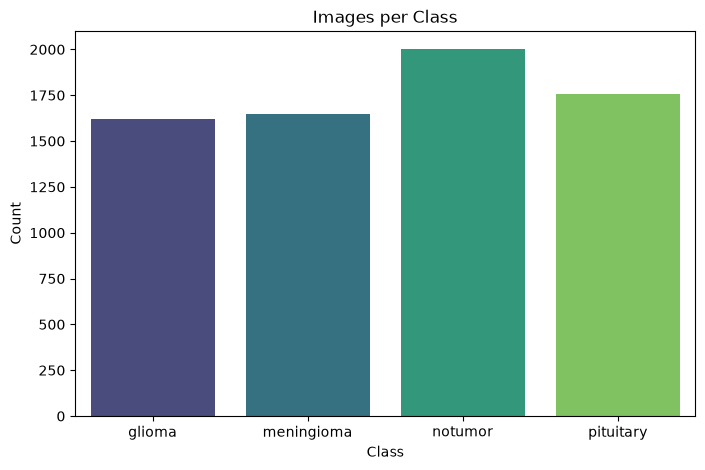

In [86]:
import matplotlib.pyplot as plt
import seaborn as sns

classes,counts = np.unique(labels,return_counts=True)


plt.figure(figsize=(8,5))
sns.barplot(x=classes, y=counts, palette="viridis")
plt.title("Images per Class")
plt.xlabel("Class")
plt.ylabel("Count")
plt.show()

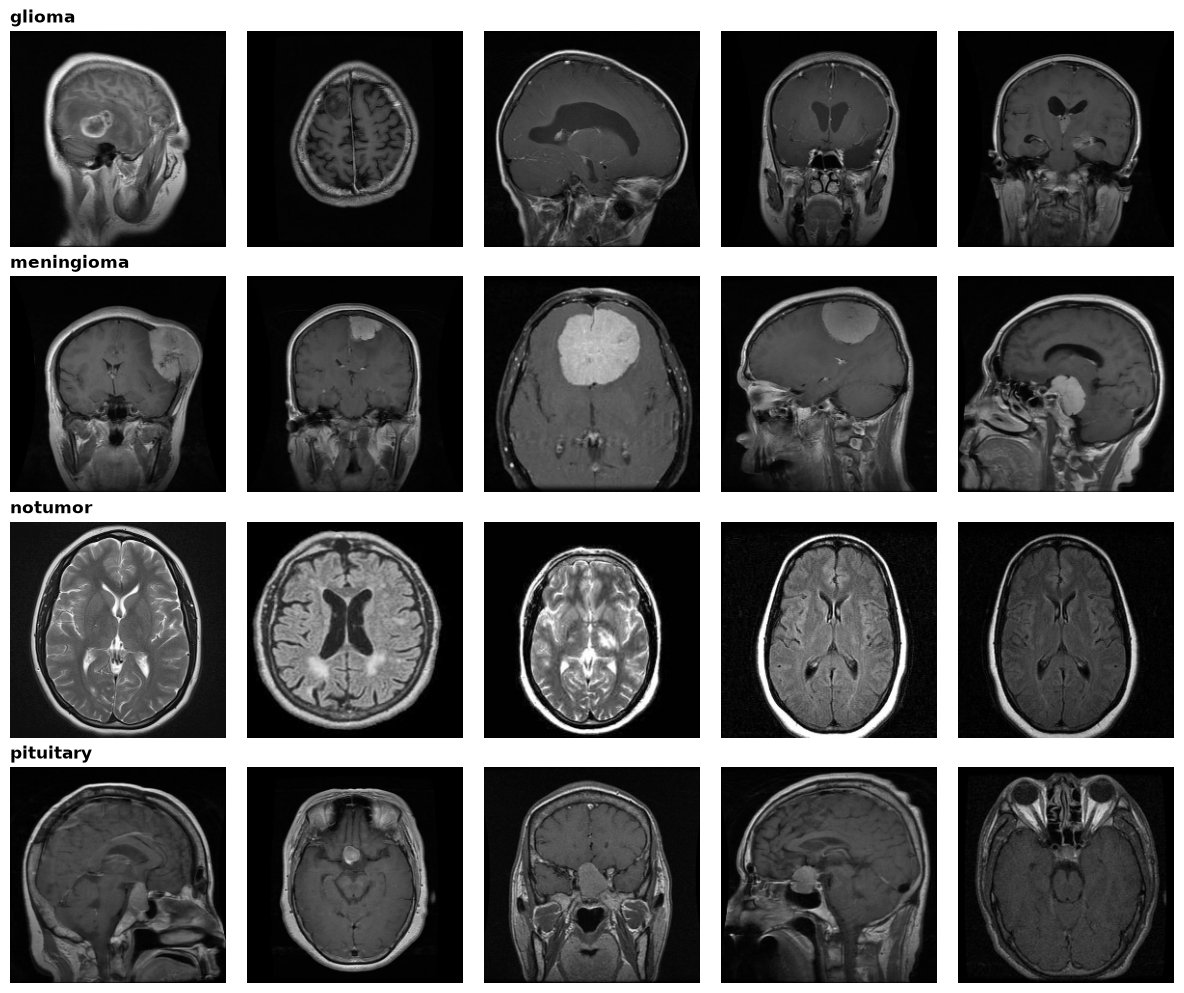

In [94]:
sample_per_class = 5
num_classes = len(classes)
import cv2


fig, axes = plt.subplots(num_classes,sample_per_class,figsize=(12,10))


for i , cls in enumerate(classes):
    class_i  = np.where(labels==cls)[0]
    for j in range(sample_per_class):
        img_i = class_i[j]
        img=images[img_i]
        
        img_rgb = cv2.cvtColor(img,cv2.COLOR_BGR2RGB)
        
        
        ax = axes[i,j]
        ax.imshow(img_rgb)
        ax.axis('off')
        if j == 0:
            ax.set_title(cls, loc='left', fontweight='bold')
            
plt.tight_layout()
plt.show()

In [95]:
p = (counts / counts.sum()) * 100
for cls, pct in zip(classes, p):
    print(f"{cls}: {pct:.1f}%")

glioma: 23.1%
meningioma: 23.4%
notumor: 28.5%
pituitary: 25.0%


In [ ]:
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.utils import to_categorical

encoder = LabelEncoder()
labels_encoded = encoder.fit_transform(labels)

class_named = encoder.classes_
# print(class_named)

labels_onhot = to_categorical(labels_encoded)

np.savez_compressed('data/processed/dataset.npz',images=images,labels=labels_onhot,classes=class_named)

for idx, name in enumerate(class_named):
    print(f"  {name} ---> {idx} ---> {to_categorical(idx, num_classes=len(class_named))}")
    
print(f"\nOne-hot array shape: {labels_onhot.shape}")
sample_idx = 0
print(f"\nExample label before encoding: {labels[sample_idx]}")
print(f"Example label after integer encoding: {labels_encoded[sample_idx]}")
print(f"Example label after one-hot encoding: {labels_onhot[sample_idx]}")



  glioma ---> 0 ---> [1. 0. 0. 0.]
  meningioma ---> 1 ---> [0. 1. 0. 0.]
  notumor ---> 2 ---> [0. 0. 1. 0.]
  pituitary ---> 3 ---> [0. 0. 0. 1.]

One-hot array shape: (7023, 4)

Example label before encoding: notumor
Example label after integer encoding: 2
Example label after one-hot encoding: [0. 0. 1. 0.]


In [98]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test = train_test_split(
    images,labels_onhot,
    test_size=0.2,stratify=labels_encoded,
    random_state=42
)

print("arrays sheap : ")

print("X_train : ", X_train.shape)
print("X_test : ", X_test.shape)
print("y_train : ", y_train.shape)
print("y_test : ", y_test.shape)


print("check distributions ")

for idx , name in enumerate(class_named):
    train_count = np.sum(np.argmax(y_train, axis=1) == idx)
    test_count = np.sum(np.argmax(y_test, axis=1) == idx)
    
    train_pct = (train_count / len(y_train)) * 100
    test_pct = (test_count / len(y_test)) * 100
    
    print(f"{name}:")
    print(f"  Train: {train_pct:.2f}%")
    print(f"  Test:  {test_pct:.2f}%")

arrays sheap : 
X_train :  (5618, 224, 224, 3)
X_test :  (1405, 224, 224, 3)
y_train :  (5618, 4)
y_test :  (1405, 4)
check distributions 
glioma:
  Train: 23.09%
  Test:  23.06%
meningioma:
  Train: 23.42%
  Test:  23.42%
notumor:
  Train: 28.48%
  Test:  28.47%
pituitary:
  Train: 25.01%
  Test:  25.05%


In [99]:
y_train_int = np.argmax(y_train,axis=1)



X_train,X_val,y_train,y_val = train_test_split(
    X_train,y_train,
    test_size=0.15,
    stratify=y_train_int,
    random_state=42
    )

print("Shapes :")
print("X_train:", X_train.shape)
print("*"*50)
print("X_val:  ", X_val.shape)
print("*"*50)
print("X_test: ", X_test.shape)
print("*"*50)
print("y_train:", y_train.shape)
print("*"*50)
print("y_val:  ", y_val.shape)
print("*"*50)
print("y_test: ", y_test.shape)

Shapes :
X_train: (4775, 224, 224, 3)
**************************************************
X_val:   (843, 224, 224, 3)
**************************************************
X_test:  (1405, 224, 224, 3)
**************************************************
y_train: (4775, 4)
**************************************************
y_val:   (843, 4)
**************************************************
y_test:  (1405, 4)


In [100]:
print("\n--- Class Distribution Percentages (Train / Val / Test) ---")
for idx, name in enumerate(class_named):
    train_count = np.sum(np.argmax(y_train, axis=1) == idx)
    val_count = np.sum(np.argmax(y_val, axis=1) == idx)
    test_count = np.sum(np.argmax(y_test, axis=1) == idx)
    
    train_pct = (train_count / len(y_train)) * 100
    val_pct = (val_count / len(y_val)) * 100
    test_pct = (test_count / len(y_test)) * 100
    
    print(f"{name}:")
    print(f"  Train: {train_pct:.2f}%")
    print(f"  Val:   {val_pct:.2f}%")
    print(f"  Test:  {test_pct:.2f}%")


--- Class Distribution Percentages (Train / Val / Test) ---
glioma:
  Train: 23.08%
  Val:   23.13%
  Test:  23.06%
meningioma:
  Train: 23.43%
  Val:   23.37%
  Test:  23.42%
notumor:
  Train: 28.48%
  Val:   28.47%
  Test:  28.47%
pituitary:
  Train: 25.01%
  Val:   25.03%
  Test:  25.05%


Training Set: 4,775 => 67.99%

Validation Set: 843 images 12.00%

Test Set: 1,405 images 20.01%

In [101]:
np.savez_compressed(
    'data/processed/dataset.npz',
    X_train=X_train,
    y_train=y_train,
    X_val=X_val,
    y_val=y_val,
    X_test=X_test,
    y_test=y_test,
    class_named=class_named
)

print("split data saved in : 'data/processed/dataset.npz'")


if 'images' in locals():
    del images
    
if 'labels' in locals():
    del labels
    
    
X_train = X_train.astype("float32") / 255.0
X_val = X_val.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

for name, arr in [("X_train", X_train), ("X_val", X_val), ("X_test", X_test)]:
    print(f"{name} -> dtype: {arr.dtype}, min: {arr.min():.1f}, max: {arr.max():.1f}")

split data saved in : 'data/processed/dataset.npz'
X_train -> dtype: float32, min: 0.0, max: 1.0
X_val -> dtype: float32, min: 0.0, max: 1.0
X_test -> dtype: float32, min: 0.0, max: 1.0


In [102]:
print(os.getcwd())

/app
